In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


In [3]:
data = pd.read_csv("HousePricePrediction.csv")

In [4]:
data

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2914,2914,160,RM,1936,Inside,Twnhs,7,1970,1970,CemntBd,0.0,546.0,NaN
2915,2915,160,RM,1894,Inside,TwnhsE,5,1970,1970,CemntBd,0.0,546.0,NaN
2916,2916,20,RL,20000,Inside,1Fam,7,1960,1996,VinylSd,0.0,1224.0,NaN
2917,2917,85,RL,10441,Inside,1Fam,5,1992,1992,HdBoard,0.0,912.0,NaN


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Id            2919 non-null   int64  
 1   MSSubClass    2919 non-null   int64  
 2   MSZoning      2915 non-null   str    
 3   LotArea       2919 non-null   int64  
 4   LotConfig     2919 non-null   str    
 5   BldgType      2919 non-null   str    
 6   OverallCond   2919 non-null   int64  
 7   YearBuilt     2919 non-null   int64  
 8   YearRemodAdd  2919 non-null   int64  
 9   Exterior1st   2918 non-null   str    
 10  BsmtFinSF2    2918 non-null   float64
 11  TotalBsmtSF   2918 non-null   float64
 12  SalePrice     1460 non-null   float64
dtypes: float64(3), int64(6), str(4)
memory usage: 352.3 KB


In [6]:
data.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           4
LotArea            0
LotConfig          0
BldgType           0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
Exterior1st        1
BsmtFinSF2         1
TotalBsmtSF        1
SalePrice       1459
dtype: int64

In [7]:
data.describe()


,Id,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,SalePrice
count,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2918.000000,2918.000000,1460.000000
mean,1459.000000,57.137718,10168.114080,5.564577,1971.312778,1984.264474,49.582248,1051.777587,180921.195890
std,842.787043,42.517628,7886.996359,1.113131,30.291442,20.894344,169.205611,440.766258,79442.502883
min,0.000000,20.000000,1300.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,34900.000000
25%,729.500000,20.000000,7478.000000,5.000000,1953.500000,1965.000000,0.000000,793.000000,129975.000000
50%,1459.000000,50.000000,9453.000000,5.000000,1973.000000,1993.000000,0.000000,989.500000,163000.000000
75%,2188.500000,70.000000,11570.000000,6.000000,2001.000000,2004.000000,0.000000,1302.000000,214000.000000
max,2918.000000,190.000000,215245.000000,9.000000,2010.000000,2010.000000,1526.000000,6110.000000,755000.000000


In [8]:
print("Total records:", len(data))

print(
    "Records with SalePrice:",
    data['SalePrice'].notnull().sum()
)

print(
    "Records without SalePrice:",
    data['SalePrice'].isnull().sum()
)

Total records: 2919
Records with SalePrice: 1460
Records without SalePrice: 1459


In [9]:
print(data[['Id', 'SalePrice']].tail(10))

        Id  SalePrice
2909  2909        NaN
2910  2910        NaN
2911  2911        NaN
2912  2912        NaN
2913  2913        NaN
2914  2914        NaN
2915  2915        NaN
2916  2916        NaN
2917  2917        NaN
2918  2918        NaN


In [10]:
print(data[data['SalePrice'].isnull()]['Id'].head(10))

1460    1460
1461    1461
1462    1462
1463    1463
1464    1464
1465    1465
1466    1466
1467    1467
1468    1468
1469    1469
Name: Id, dtype: int64


In [11]:
missing_columns = [
    'MSZoning',
    'Exterior1st',
    'BsmtFinSF2',
    'TotalBsmtSF'
]

for col in missing_columns:

    print("\nColumn:", col)

    print(
        data[data[col].isnull()]
    )


Column: MSZoning
        Id  MSSubClass MSZoning  LotArea LotConfig BldgType  OverallCond  \
1915  1915          30      NaN    21780    Inside     1Fam            4   
2216  2216          20      NaN    14584    Inside     1Fam            5   
2250  2250          70      NaN    56600    Inside     1Fam            1   
2904  2904          20      NaN    31250    Inside     1Fam            3   

      YearBuilt  YearRemodAdd Exterior1st  BsmtFinSF2  TotalBsmtSF  SalePrice  
1915       1910          1950     Wd Sdng         0.0          0.0        NaN  
2216       1952          1952     AsbShng         0.0          0.0        NaN  
2250       1900          1950     Wd Sdng         0.0        686.0        NaN  
2904       1951          1951      CBlock         0.0          0.0        NaN  

Column: Exterior1st
        Id  MSSubClass MSZoning  LotArea LotConfig BldgType  OverallCond  \
2151  2151          30       RL    19550    Inside     1Fam            7   

      YearBuilt  YearRemodA

In [12]:
# Check the frequency of each category in MSZoning
# dropna=False ensures that missing values are also included in the count

data['MSZoning'].value_counts(dropna=False)

MSZoning
RL         2265
RM          460
FV          139
RH           26
C (all)      25
NaN           4
Name: count, dtype: int64

In [13]:
# Check the frequency of each category in Exterior1st
# Helps us identify the most common exterior type

data['Exterior1st'].value_counts(dropna=False)

Exterior1st
VinylSd    1025
MetalSd     450
HdBoard     442
Wd Sdng     411
Plywood     221
CemntBd     126
BrkFace      87
WdShing      56
AsbShng      44
Stucco       43
BrkComm       6
AsphShn       2
Stone         2
CBlock        2
ImStucc       1
NaN           1
Name: count, dtype: int64

In [14]:
# Find all columns containing the word 'Bsmt'
# Helps us identify which basement-related features are available
[col for col in data.columns if 'Bsmt' in col]

['BsmtFinSF2', 'TotalBsmtSF']

In [15]:
# Display all details of the house whose Id is 2120
# .T transposes the output, making it easier to inspect the row vertically
data[data['Id'] == 2120].T

,2120
Id,2120
MSSubClass,20
MSZoning,RM
LotArea,5940
LotConfig,FR3
BldgType,1Fam
OverallCond,7
YearBuilt,1946
YearRemodAdd,1950
Exterior1st,MetalSd


In [16]:
# Create training data by selecting rows where SalePrice is NOT missing
# These rows contain the actual house prices that our model will learn from
# .copy() creates an independent copy of the selected data
train_data = data[data['SalePrice'].notnull()].copy()

# Create testing data by selecting rows where SalePrice IS missing
# These rows contain houses whose prices we want our model to predict
# We must not delete these rows or fill their SalePrice values
test_data = data[data['SalePrice'].isnull()].copy()

print("Training data missing values:")
print(train_data.isnull().sum())

print("\nTesting data missing values:")
print(test_data.isnull().sum())

Training data missing values:
Id              0
MSSubClass      0
MSZoning        0
LotArea         0
LotConfig       0
BldgType        0
OverallCond     0
YearBuilt       0
YearRemodAdd    0
Exterior1st     0
BsmtFinSF2      0
TotalBsmtSF     0
SalePrice       0
dtype: int64

Testing data missing values:
Id                 0
MSSubClass         0
MSZoning           4
LotArea            0
LotConfig          0
BldgType           0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
Exterior1st        1
BsmtFinSF2         1
TotalBsmtSF        1
SalePrice       1459
dtype: int64


In [17]:
# 1. Find replacement values using training data

mszoning_mode = train_data['MSZoning'].mode()[0]

exterior_mode = train_data['Exterior1st'].mode()[0]

bsmtfin_median = train_data['BsmtFinSF2'].median()

totalbsmt_median = train_data['TotalBsmtSF'].median()


# 2. Fill missing values in testing data

test_data['MSZoning'] = test_data['MSZoning'].fillna(mszoning_mode)

test_data['Exterior1st'] = test_data['Exterior1st'].fillna(exterior_mode)

test_data['BsmtFinSF2'] = test_data['BsmtFinSF2'].fillna(bsmtfin_median)

test_data['TotalBsmtSF'] = test_data['TotalBsmtSF'].fillna(totalbsmt_median)

In [18]:
# Display missing values in training data
# We expect no missing values in our current training dataset
print("Training data missing values:")
print(train_data.isnull().sum())

# Display missing values in testing data
# We expect missing feature values here, but SalePrice will remain missing
print("\nTesting data missing values:")
print(test_data.isnull().sum())

Training data missing values:
Id              0
MSSubClass      0
MSZoning        0
LotArea         0
LotConfig       0
BldgType        0
OverallCond     0
YearBuilt       0
YearRemodAdd    0
Exterior1st     0
BsmtFinSF2      0
TotalBsmtSF     0
SalePrice       0
dtype: int64

Testing data missing values:
Id                 0
MSSubClass         0
MSZoning           0
LotArea            0
LotConfig          0
BldgType           0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
Exterior1st        0
BsmtFinSF2         0
TotalBsmtSF        0
SalePrice       1459
dtype: int64


In [20]:
print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

print("\nDuplicate rows in training data:", train_data.duplicated().sum())
print("Duplicate rows in testing data:", test_data.duplicated().sum())

print("\nUnique values in categorical columns:")

# Select columns containing string data
categorical_cols = train_data.select_dtypes(include=['str', 'object']).columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(train_data[col].unique())

Training shape: (1460, 13)
Testing shape: (1459, 13)

Duplicate rows in training data: 0
Duplicate rows in testing data: 0

Unique values in categorical columns:

MSZoning:
<ArrowStringArray>
['RL', 'RM', 'C (all)', 'FV', 'RH']
Length: 5, dtype: str

LotConfig:
<ArrowStringArray>
['Inside', 'FR2', 'Corner', 'CulDSac', 'FR3']
Length: 5, dtype: str

BldgType:
<ArrowStringArray>
['1Fam', '2fmCon', 'Duplex', 'TwnhsE', 'Twnhs']
Length: 5, dtype: str

Exterior1st:
<ArrowStringArray>
['VinylSd', 'MetalSd', 'Wd Sdng', 'HdBoard', 'BrkFace', 'WdShing', 'CemntBd',
 'Plywood', 'AsbShng',  'Stucco', 'BrkComm', 'AsphShn',   'Stone', 'ImStucc',
  'CBlock']
Length: 15, dtype: str


In [21]:
# Select numerical columns from the training dataset
numerical_cols = train_data.select_dtypes(include='number').columns

# Display descriptive statistics for numerical columns
# Includes count, mean, standard deviation, minimum,
# quartiles and maximum values
print(train_data[numerical_cols].describe().T)

               count           mean           std      min        25%  \
Id            1460.0     729.500000    421.610009      0.0     364.75   
MSSubClass    1460.0      56.897260     42.300571     20.0      20.00   
LotArea       1460.0   10516.828082   9981.264932   1300.0    7553.50   
OverallCond   1460.0       5.575342      1.112799      1.0       5.00   
YearBuilt     1460.0    1971.267808     30.202904   1872.0    1954.00   
YearRemodAdd  1460.0    1984.865753     20.645407   1950.0    1967.00   
BsmtFinSF2    1460.0      46.549315    161.319273      0.0       0.00   
TotalBsmtSF   1460.0    1057.429452    438.705324      0.0     795.75   
SalePrice     1460.0  180921.195890  79442.502883  34900.0  129975.00   

                   50%        75%       max  
Id               729.5    1094.25    1459.0  
MSSubClass        50.0      70.00     190.0  
LotArea         9478.5   11601.50  215245.0  
OverallCond        5.0       6.00       9.0  
YearBuilt       1973.0    2000.00    20

In [22]:
# Check how frequently each MSSubClass value occurs
# This helps us understand why MSSubClass is categorical
print(train_data['MSSubClass'].value_counts().sort_index())

MSSubClass
20     536
30      69
40       4
45      12
50     144
60     299
70      60
75      16
80      58
85      20
90      52
120     87
160     63
180     10
190     30
Name: count, dtype: int64


In [23]:
# Check the distribution of the target variable, SalePrice
print(train_data['SalePrice'].describe())

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [24]:
# Identify potential outliers in LotArea and SalePrice using the IQR method

for col in ['LotArea', 'SalePrice']:
    Q1 = train_data[col].quantile(0.25)
    Q3 = train_data[col].quantile(0.75)

    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = train_data[(train_data[col] < lower) | (train_data[col] > upper)]

    print(f"\n{col}")
    print("Lower boundary:", lower)
    print("Upper boundary:", upper)
    print("Number of potential outliers:", len(outliers))


LotArea
Lower boundary: 1481.5
Upper boundary: 17673.5
Number of potential outliers: 69

SalePrice
Lower boundary: 3937.5
Upper boundary: 340037.5
Number of potential outliers: 61


In [25]:
# Inspect the 10 houses with the largest lot areas and sale prices

print("Largest Lot Areas:")
print(train_data.nlargest(10, 'LotArea')[['Id', 'LotArea', 'SalePrice']])

print("\nHighest Sale Prices:")
print(train_data.nlargest(10, 'SalePrice')[['Id', 'LotArea', 'SalePrice']])

Largest Lot Areas:
        Id  LotArea  SalePrice
313    313   215245   375000.0
335    335   164660   228950.0
249    249   159000   277000.0
706    706   115149   302000.0
451    451    70761   280000.0
1298  1298    63887   160000.0
1396  1396    57200   160000.0
769    769    53504   538000.0
457    457    53227   256000.0
384    384    53107   240000.0

Highest Sale Prices:
        Id  LotArea  SalePrice
691    691    21535   755000.0
1182  1182    15623   745000.0
1169  1169    35760   625000.0
898    898    12919   611657.0
803    803    13891   582933.0
1046  1046    16056   556581.0
440    440    15431   555000.0
769    769    53504   538000.0
178    178    17423   501837.0
798    798    13518   485000.0


In [26]:
# Verify that Id still contains the original house identifiers

print(train_data['Id'].head())
print(train_data['Id'].tail())
print("Minimum Id:", train_data['Id'].min())
print("Maximum Id:", train_data['Id'].max())

0    0
1    1
2    2
3    3
4    4
Name: Id, dtype: int64
1455    1455
1456    1456
1457    1457
1458    1458
1459    1459
Name: Id, dtype: int64
Minimum Id: 0
Maximum Id: 1459


In [27]:
# Separate input features (X) and target variable (y)
X = train_data.drop(columns=['Id', 'SalePrice'])
y = train_data['SalePrice']


In [28]:
# Prepare the testing features using the same columns
X_test = test_data.drop(columns=['Id', 'SalePrice'])


In [29]:
# Check the shapes of our datasets
print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_test shape:", X_test.shape)

X shape: (1460, 11)
y shape: (1460,)
X_test shape: (1459, 11)


In [30]:
# Identify categorical columns in the input features
categorical_cols = X.select_dtypes(include=['str', 'object']).columns

# Convert categorical features into numerical columns
X = pd.get_dummies(X, columns=categorical_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical_cols, dtype=int)

# Align testing columns with training columns
X_test = X_test.reindex(columns=X.columns, fill_value=0)

# Check the new shapes
print("X shape after encoding:", X.shape)
print("X_test shape after encoding:", X_test.shape)

X shape after encoding: (1460, 37)
X_test shape after encoding: (1459, 37)


In [32]:
# Split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Check the shapes after splitting
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (1168, 37)
X_val: (292, 37)
y_train: (1168,)
y_val: (292,)


In [34]:
# Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](37,)","[ 893.56, 0.69, 4334.37,...,-14559.76, -4228.81, -2879.33]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](37,)","['MSSubClass','LotArea','OverallCond',...,'Exterior1st_VinylSd', 'Exterior1st_Wd Sdng','Exterior1st_WdShing']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.998e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,37
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(33)


In [36]:
# Predict house prices using the validation dataset
y_pred = model.predict(X_val)

# Display the first 10 predicted prices
print(y_pred)

[168844.20187043 243627.93266266 114499.46802617 157672.74928531
 254809.72691561 156499.88714206 177912.63550289 127514.41651573
 133133.47244357 149402.60951089 130794.50236615 123245.60221163
  80364.27242006 239205.09970653 218458.40576163 177909.93322614
 217597.00518371 179150.77327371 135680.39694332 232757.15292119
 163631.47385308 219363.09382651 202562.61369718 154850.31244005
 223837.5082334  166839.82458251 228156.71441651 110537.33765989
 215037.51335144 205629.10183977 115051.49676838 231549.64641402
 224622.45132014 128364.14241408 251497.64742701 140828.2848385
 170989.33623265 217385.70991952 255132.48015834  77807.51078474
 118583.69813315 217906.68251222 125596.27931998 291090.36797416
 141473.5225182  105135.3471821  128070.20017551 130672.5512748
 320648.92241052 146484.9314358  112112.92648895 193792.29031158
 123203.44465363 262793.87552922 152184.80649994 259668.17086377
 181304.6833272  171336.27224219 197876.30912181  85228.38830291
  62102.9578558  209481.140

In [38]:
# Calculate R-squared and Adjusted R-squared on validation data
r2 = r2_score(y_val, y_pred)

n = X_val.shape[0]
p = X_val.shape[1]

adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("R-squared:", r2)
print("Adjusted R-squared:", adjusted_r2)

R-squared: 0.6195131796544882
Adjusted R-squared: 0.5640879341710868


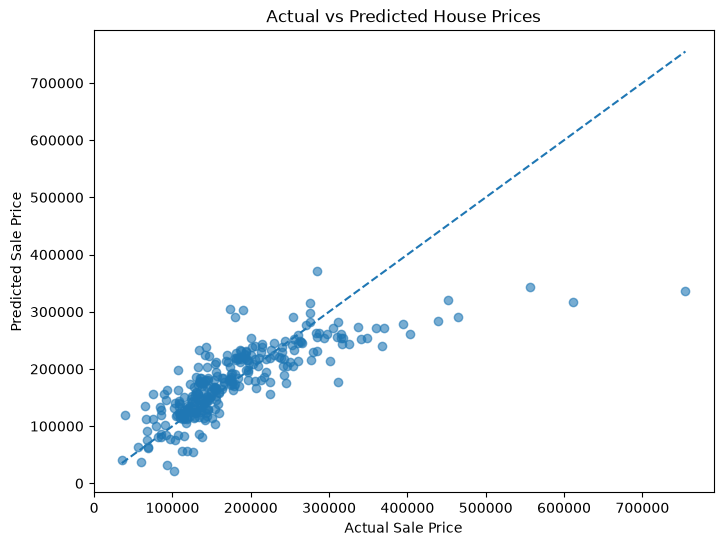

In [42]:
# Visualize actual prices against predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_val, y_pred, alpha=0.6)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    linestyle='--'
)

plt.show()